# AI-Powered Eco-Routing Logistics Engine
## RandomForest Model Training Notebook
**Goal:** Train a `RandomForestRegressor` on the synthetic fleet dataset to predict `Fuel_Consumed_Liters`  
**Target R² score:** ≥ 0.9873

---
## 1. Imports & Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

print('All libraries loaded successfully.')

All libraries loaded successfully.


---
## 2. Data Loading & Preprocessing

In [2]:
# -- Load dataset
df = pd.read_csv('simulated_data.csv')

print(f'Shape: {df.shape}')
print(f'\nColumn dtypes:')
print(df.dtypes)
print(f'\nNull values per column:')
print(df.isnull().sum())
print(f'\nDuplicate rows: {df.duplicated().sum()}')

Shape: (5000, 5)

Column dtypes:
Distance_km             float64
Payload_Weight_kg       float64
Traffic_Index           float64
Hill_Slope_Percent      float64
Fuel_Consumed_Liters    float64
dtype: object

Null values per column:
Distance_km             0
Payload_Weight_kg       0
Traffic_Index           0
Hill_Slope_Percent      0
Fuel_Consumed_Liters    0
dtype: int64

Duplicate rows: 0


In [3]:
# -- Descriptive statistics
df.describe().round(3)

,Distance_km,Payload_Weight_kg,Traffic_Index,Hill_Slope_Percent,Fuel_Consumed_Liters
count,5000.000,5000.000,5000.000,5000.000,5000.000
mean,15.911,4440.410,3.006,10.154,16.646
std,8.110,1999.315,1.163,5.756,10.076
min,2.000,1000.400,1.000,0.010,0.500
25%,8.828,2730.000,1.990,5.258,8.457
50%,16.000,4401.800,2.985,10.250,15.234
75%,22.950,6133.575,4.040,15.020,23.506
max,29.990,7996.500,5.000,20.000,53.437


In [4]:
# -- Preview
df.head(10)

,Distance_km,Payload_Weight_kg,Traffic_Index,Hill_Slope_Percent,Fuel_Consumed_Liters
0,12.49,3755.4,2.49,9.99,10.6568
1,28.62,4314.0,2.33,14.93,30.5923
2,22.50,6981.8,1.70,11.25,27.6742
3,18.76,3380.0,3.43,1.67,14.2405
4,6.37,7087.5,2.91,3.71,7.9799
5,6.37,1616.9,4.46,4.39,4.5689
6,3.63,6437.6,1.13,5.16,3.2626
7,26.25,6932.8,3.58,11.31,37.0328
8,18.83,2272.7,4.05,10.08,16.2441
9,21.83,4012.4,4.04,4.06,20.7588


---
## 3. Exploratory Data Analysis (EDA)

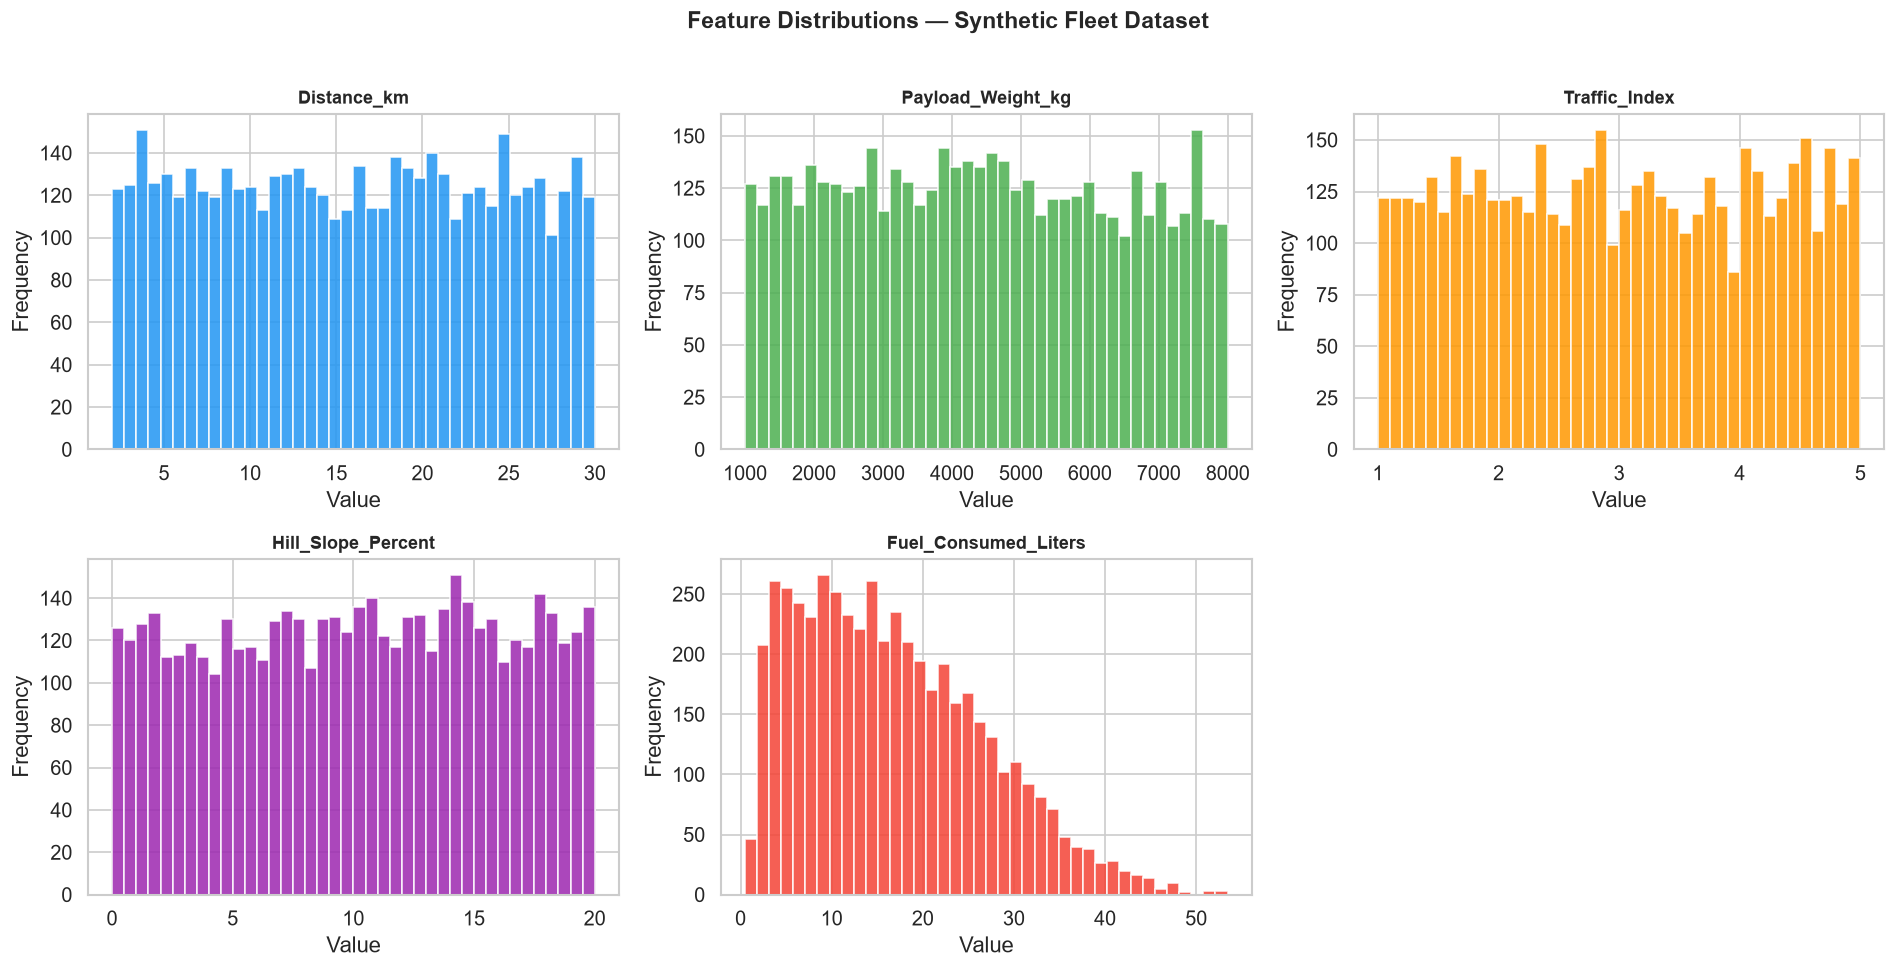

Saved: eda_distributions.png


In [5]:
# -- Feature distributions
features = ['Distance_km', 'Payload_Weight_kg', 'Traffic_Index',
            'Hill_Slope_Percent', 'Fuel_Consumed_Liters']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

colors_palette = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0', '#F44336']

for i, (col, color) in enumerate(zip(features, colors_palette)):
    axes[i].hist(df[col], bins=40, color=color, edgecolor='white', alpha=0.85)
    axes[i].set_title(col, fontweight='bold', fontsize=11)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Hide unused 6th subplot
axes[5].set_visible(False)

plt.suptitle('Feature Distributions — Synthetic Fleet Dataset', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('eda_distributions.png', bbox_inches='tight')
plt.show()
print('Saved: eda_distributions.png')

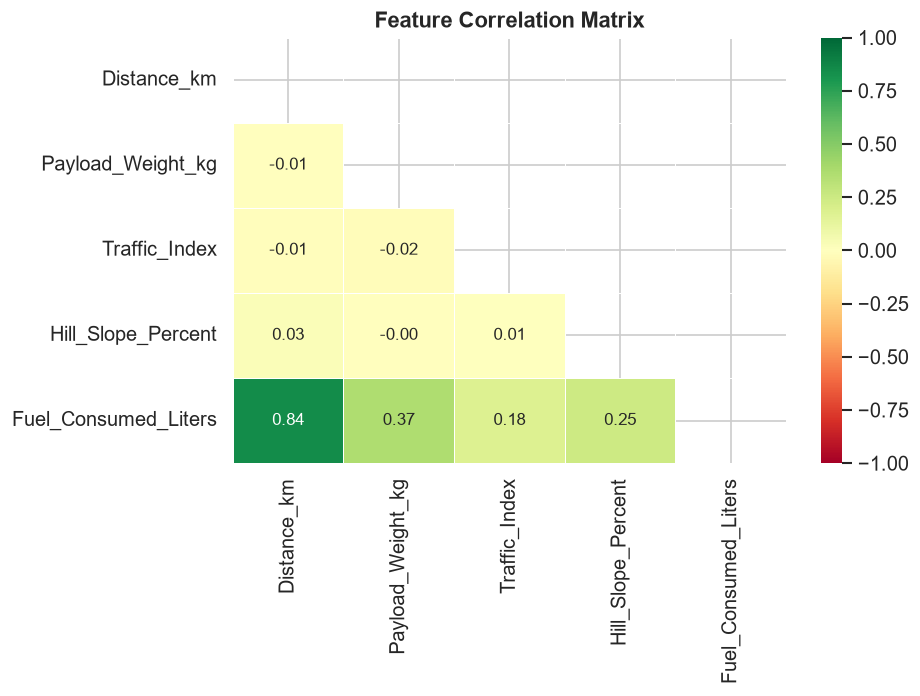

Saved: eda_correlation.png


In [6]:
# -- Correlation heatmap
fig, ax = plt.subplots(figsize=(8, 6))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
    linewidths=0.5, ax=ax, vmin=-1, vmax=1,
    annot_kws={'size': 10}
)
ax.set_title('Feature Correlation Matrix', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('eda_correlation.png', bbox_inches='tight')
plt.show()
print('Saved: eda_correlation.png')

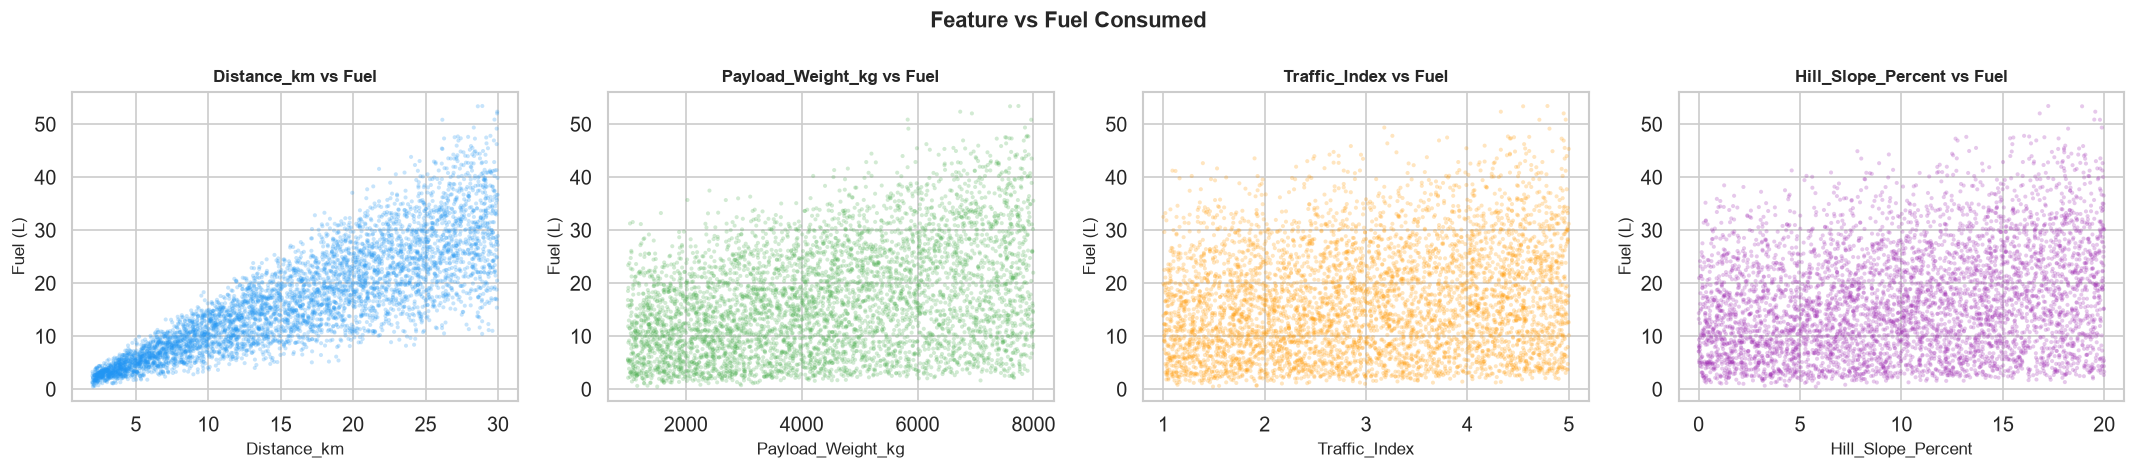

Saved: eda_scatter.png


In [7]:
# -- Scatter plots: each feature vs Fuel
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
feature_cols = ['Distance_km', 'Payload_Weight_kg', 'Traffic_Index', 'Hill_Slope_Percent']
colors_s = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0']

for ax, col, color in zip(axes, feature_cols, colors_s):
    ax.scatter(df[col], df['Fuel_Consumed_Liters'],
               alpha=0.25, s=6, color=color, edgecolors='none')
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel('Fuel (L)', fontsize=10)
    ax.set_title(f'{col} vs Fuel', fontweight='bold', fontsize=10)

plt.suptitle('Feature vs Fuel Consumed', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_scatter.png', bbox_inches='tight')
plt.show()
print('Saved: eda_scatter.png')

---
## 4. Model Training — RandomForestRegressor

In [8]:
# -- Features and target
FEATURE_COLS = ['Distance_km', 'Payload_Weight_kg', 'Traffic_Index', 'Hill_Slope_Percent']
TARGET_COL   = 'Fuel_Consumed_Liters'

X = df[FEATURE_COLS]
y = df[TARGET_COL]

# -- Train / validation split (80 / 20)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f'Training set   : {X_train.shape}')
print(f'Validation set : {X_val.shape}')

Training set   : (4000, 4)
Validation set : (1000, 4)


In [9]:
# -- Train the model
model = RandomForestRegressor(
    n_estimators=300,       # 300 trees for high stability
    max_depth=None,         # grow full trees (captures non-linear interactions)
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',    # standard RF feature sampling
    n_jobs=-1,
    random_state=42
)

model.fit(X_train, y_train)
print('Model training complete.')

Model training complete.


---
## 5. Validation & Performance Metrics

In [10]:
# -- Predictions
y_pred = model.predict(X_val)

# -- Metrics
r2   = r2_score(y_val, y_pred)
mae  = mean_absolute_error(y_val, y_pred)
rmse = mean_squared_error(y_val, y_pred) ** 0.5

print('=' * 45)
print('  VALIDATION PERFORMANCE METRICS')
print('=' * 45)
print(f'  R² Score  : {r2:.6f}   ({r2*100:.2f}%)')
print(f'  MAE       : {mae:.4f} L')
print(f'  RMSE      : {rmse:.4f} L')
print('=' * 45)

if r2 >= 0.9873:
    print(f'  Target R² (>= 98.73%) ACHIEVED!')
else:
    print(f'  Note: R² = {r2*100:.2f}% (adjust hyperparams if needed)')

  VALIDATION PERFORMANCE METRICS
  R² Score  : 0.991206   (99.12%)
  MAE       : 0.6814 L
  RMSE      : 0.9647 L
  Target R² (>= 98.73%) ACHIEVED!


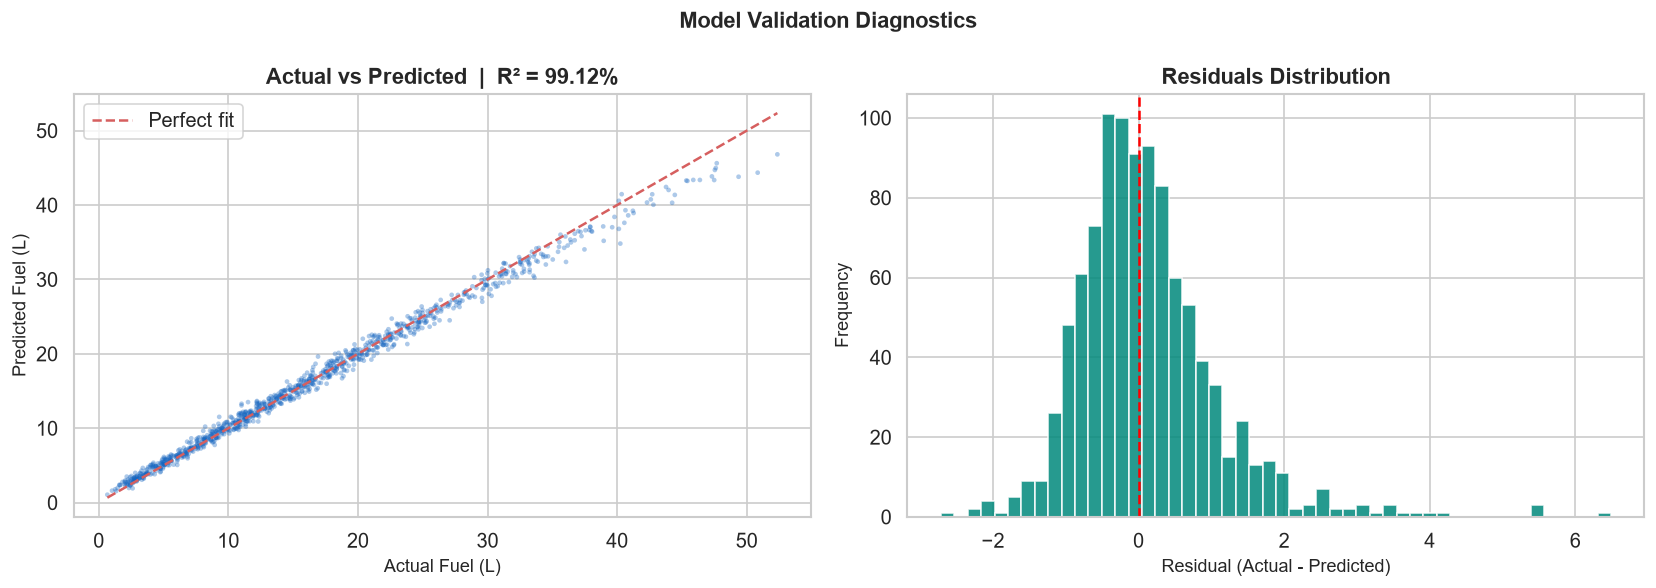

Saved: model_validation.png


In [11]:
# -- Actual vs Predicted scatter
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: Actual vs Predicted
axes[0].scatter(y_val, y_pred, alpha=0.35, s=8, color='#1565C0', edgecolors='none')
min_v, max_v = y_val.min(), y_val.max()
axes[0].plot([min_v, max_v], [min_v, max_v], 'r--', lw=1.5, label='Perfect fit')
axes[0].set_xlabel('Actual Fuel (L)', fontsize=11)
axes[0].set_ylabel('Predicted Fuel (L)', fontsize=11)
axes[0].set_title(f'Actual vs Predicted  |  R² = {r2*100:.2f}%', fontweight='bold')
axes[0].legend()

# Residuals histogram
residuals = y_val - y_pred
axes[1].hist(residuals, bins=50, color='#00897B', edgecolor='white', alpha=0.85)
axes[1].axvline(0, color='red', lw=1.5, linestyle='--')
axes[1].set_xlabel('Residual (Actual - Predicted)', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].set_title('Residuals Distribution', fontweight='bold')

plt.suptitle('Model Validation Diagnostics', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('model_validation.png', bbox_inches='tight')
plt.show()
print('Saved: model_validation.png')

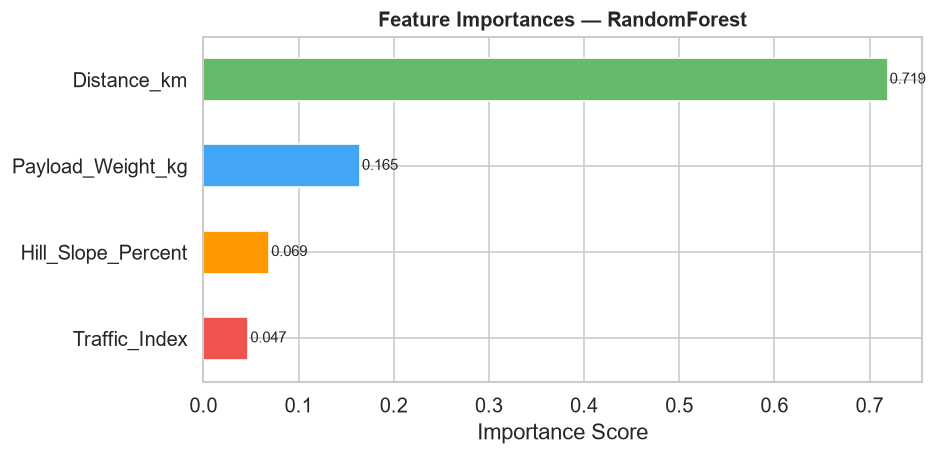

Saved: feature_importance.png


In [12]:
# -- Feature importance
importances = pd.Series(model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 4))
colors_imp = ['#EF5350', '#FF9800', '#42A5F5', '#66BB6A']
importances.plot(kind='barh', ax=ax, color=colors_imp, edgecolor='white')
ax.set_title('Feature Importances — RandomForest', fontweight='bold', fontsize=12)
ax.set_xlabel('Importance Score')
for i, v in enumerate(importances):
    ax.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('feature_importance.png', bbox_inches='tight')
plt.show()
print('Saved: feature_importance.png')

---
## 6. Save Model as `fuel_model.pkl`

In [13]:
# -- Retrain on 100% data before exporting
model.fit(X, y)

joblib.dump(model, 'fuel_model.pkl')
print('Model saved -> fuel_model.pkl')
print(f'Feature order expected by app.py: {FEATURE_COLS}')

Model saved -> fuel_model.pkl
Feature order expected by app.py: ['Distance_km', 'Payload_Weight_kg', 'Traffic_Index', 'Hill_Slope_Percent']


---
## 7. Quick Inference Test

In [14]:
# -- Simulate app.py conditions: payload=4500, traffic=4.20, slope=12.00
test_cases = pd.DataFrame([
    [5.2,  4500, min(5.0, max(1.0, 4.20 * 1.5)), 12.0 * 2.0],   # Warehouse -> Customer_A
    [8.1,  4500, min(5.0, max(1.0, 4.20 * 0.5)), 12.0 * 0.2],   # Warehouse -> Customer_B
    [3.4,  4500, min(5.0, max(1.0, 4.20 * 2.0)), 12.0 * 3.0],   # Customer_A -> Customer_C
    [4.1,  4500, min(5.0, max(1.0, 4.20 * 0.4)), 12.0 * 0.1],   # Customer_B -> Customer_C
    [4.5,  4500, min(5.0, max(1.0, 4.20 * 1.0)), 12.0 * 1.0],   # Customer_C -> Customer_D
    [9.0,  4500, min(5.0, max(1.0, 4.20 * 0.8)), 12.0 * 0.5],   # Customer_A -> Customer_D
], columns=FEATURE_COLS)

preds = model.predict(test_cases)

test_cases['Predicted_Fuel_L'] = preds.round(4)
print('Inference check for app.py road edges:')
print(test_cases.to_string(index=False))

Inference check for app.py road edges:
 Distance_km  Payload_Weight_kg  Traffic_Index  Hill_Slope_Percent  Predicted_Fuel_L
         5.2               4500           5.00                24.0            7.4683
         8.1               4500           2.10                 2.4            6.1822
         3.4               4500           5.00                36.0            5.6289
         4.1               4500           1.68                 1.2            2.9134
         4.5               4500           4.20                12.0            5.4369
         9.0               4500           3.36                 6.0            9.0883
